# Tier 4: the C++ core, hands on

Tiers 1 to 3 are Python and NumPy. This tier ports the three pricers that do the most arithmetic
(Black-Scholes, Monte Carlo and the binomial tree) to **C++20**, and calls them from Python
through **pybind11**. Python stays the interface; C++ does the loops.

```
cpp/include/ope/   the headers: what each function takes and returns
cpp/src/           black_scholes.cpp, monte_carlo.cpp, tree.cpp
cpp/python/        module.cpp, the pybind11 bindings -> the compiled module ope._core
cpp/tests/         GoogleTest, the C++ unit tests
cpp/bench/         Google Benchmark
src/ope/cpp.py     the same function names and signatures as the Python side
```

`pip install` (or `uv sync`) compiles everything: scikit-build-core runs CMake from the same
`pyproject.toml`. Then `ope.price` is the NumPy version and `ope.cpp.price` the C++ one, called
the same way. This notebook checks that they agree, explains why they can't agree to the last
bit, and measures what C++ buys.

In [ ]:
import timeit

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

import ope
from ope import _core, cpp

print(f"compiled module: {_core.__file__.split('/')[-1]}")
print(f"build: {cpp.build_type}, compiler: {_core.compiler}")
print(f"hardware threads: {cpp.hardware_threads()}")

hull = (42.0, 40.0, 0.5, 0.10, 0.20)  # S, K, T, r, sigma


def best_ms(fn, repeat=5):
    """fastest of `repeat` timed calls, in milliseconds (the least disturbed run)"""
    return 1e3 * min(timeit.repeat(fn, number=1, repeat=repeat))

compiled module: _core.cpython-312-x86_64-linux-gnu.so
build: Release, compiler: GNU 13.3.0
hardware threads: 8


## 1. One function, two languages

Hull's call priced by both sides. The numbers agree to about 14 digits, not 16. Three things
differ in the last bits, and none of them is a bug:

- **N(x):** Python uses SciPy's `ndtr`, C++ uses `0.5·erfc(−x/√2)`. Both are accurate to about
  1 unit in the last place, but not the *same* last place.
- **exp and log:** NumPy ships its own vectorized versions; C++ calls the C library.
- **Summation order:** adding the same numbers in a different order rounds differently,
  because floating-point addition isn't associative.

The gap below looks like 12 units in the last place of the price, but the price is a
difference of two legs near 30 (S·N(d1) = 32.72 and K·e^(−rT)·N(d2) = 27.96). At their scale the
gap is 1.5 units: the subtraction makes it look bigger. The tests compare within a tolerance
(`1e-11` relative, `1e-12` absolute).

In [ ]:
py, cc = ope.price("call", *hull), cpp.price("call", *hull)
print(f"Python  {py:.16f}")
print(f"C++     {cc:.16f}")
print(f"gap     {abs(py - cc):.1e}  ({abs(py - cc) / np.spacing(py):.0f} units in the last place)")

gp, gc = ope.greeks("put", *hull), cpp.greeks("put", *hull)
for name in ("delta", "gamma", "vega", "theta", "rho"):
    a, b = getattr(gp, name), getattr(gc, name)
    print(f"{name:6s} Python {a: .12f}   C++ {b: .12f}   gap {abs(a - b):.1e}")

Python  4.7594223928715316
C++     4.7594223928715422
gap     1.1e-14  (12 units in the last place)
delta  Python -0.220868709057   C++ -0.220868709057   gap 2.8e-17
gamma  Python  0.049962670406   C++  0.049962670406   gap 0.0e+00
vega   Python  8.813415059603   C++  8.813415059603   gap 0.0e+00
theta  Python -0.754174496590   C++ -0.754174496590   gap 2.2e-16
rho    Python -5.042542576654   C++ -5.042542576654   gap 1.8e-15


## 2. A whole chain in one call

The bindings take NumPy arrays, so one call prices a whole option chain: Python hands C++ six
arrays (S, K, T, r, σ, q, broadcast to the same length) and gets one array back. Below, 10,000
strikes from deep in the money to far out of the money.

largest gap 2.8e-14, at K = 76.0 where the call is worth 28.64
identical to the last bit: 57% of the strikes
largest gap in units of the last place of S = 100: 2.0


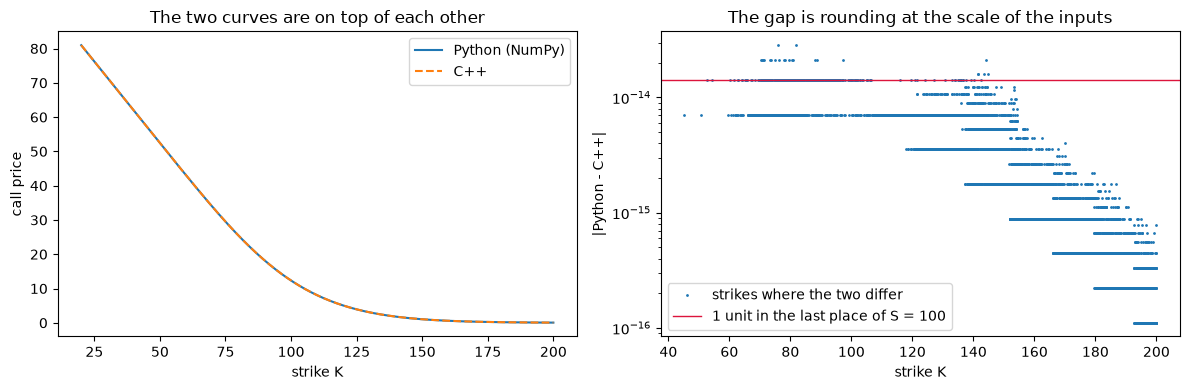

In [3]:
K = np.linspace(20, 200, 10_000)
a = np.asarray(ope.price("call", 100, K, 1.0, 0.05, 0.25))
b = np.asarray(cpp.price("call", 100, K, 1.0, 0.05, 0.25))
gap = np.abs(a - b)
i = gap.argmax()
print(f"largest gap {gap.max():.1e}, at K = {K[i]:.1f} where the call is worth {a[i]:.2f}")
print(f"identical to the last bit: {(gap == 0).mean():.0%} of the strikes")
print(f"largest gap in units of the last place of S = 100: {gap.max() / np.spacing(100.0):.1f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(K, a, label="Python (NumPy)")
ax1.plot(K, b, "--", label="C++")
ax1.set_xlabel("strike K")
ax1.set_ylabel("call price")
ax1.set_title("The two curves are on top of each other")
ax1.legend()
nz = gap > 0  # the exact matches have no place on a log scale
ax2.semilogy(K[nz], gap[nz], ".", ms=2, label="strikes where the two differ")
ax2.axhline(np.spacing(100.0), color="crimson", lw=1, label="1 unit in the last place of S = 100")
ax2.set_xlabel("strike K")
ax2.set_ylabel("|Python - C++|")
ax2.set_title("The gap is rounding at the scale of the inputs")
ax2.legend()
plt.tight_layout()
plt.show()

## 3. The tree, where C++ wins big

The tree is the same backward induction in both languages, and the prices agree to about 15
digits. The speeds differ: the Python version runs a Python loop over the time
steps, with a few NumPy operations per step, so Python's overhead is paid 2,000 times. The C++
version is two plain nested loops on one array, updated in place.

In [ ]:
args = (50.0, 50.0, 5 / 12, 0.10, 0.40)  # hull's American put
print(" steps   Python price      C++ price         gap      Python ms   C++ ms")
for steps in (5, 100, 500, 2000):
    a = ope.crr_price("put", *args, steps=steps, american=True)
    b = cpp.crr_price("put", *args, steps=steps, american=True)
    ta = best_ms(lambda n=steps: ope.crr_price("put", *args, steps=n, american=True), 3)
    tb = best_ms(lambda n=steps: cpp.crr_price("put", *args, steps=n, american=True), 3)
    print(f"{steps:6d}   {a:.12f}   {b:.12f}   {abs(a - b):.1e}   {ta:8.2f}   {tb:7.3f}")

 steps   Python price      C++ price         gap      Python ms   C++ ms
     5   4.488458534726   4.488458534726   0.0e+00       0.05     0.001
   100   4.278058548145   4.278058548145   0.0e+00       0.91     0.007
   500   4.283021276450   4.283021276450   0.0e+00       5.38     0.085
  2000   4.283922344977   4.283922344977   0.0e+00      34.78     1.126


## 4. Random numbers that any thread can reach

C++ can't reproduce NumPy's random stream (NumPy uses PCG64 plus its own normal sampler). The
C++ side has its own generator, chosen for threads: **Philox**, a *counter-based* generator.
It works like a keyed scrambler: `block = philox(counter, key)`. The key is the seed, the
counter says which block. Each block gives 4 random 64-bit integers, turned into 4 standard
normals by Box-Muller:

$$z_1 = \sqrt{-2\ln u_1}\,\cos(2\pi u_2), \qquad z_2 = \sqrt{-2\ln u_1}\,\sin(2\pi u_2)$$

There is no state to pass from one draw to the next, so normal number 1,000,000 costs the same as
normal number 0: compute block 250,000. A thread starting halfway through needs nothing from the
threads before it. NumPy ships the same Philox, so we can check the C++ version bit for bit.

numpy: ['0x6096ca00b04d3c5a', '0xb748a3261f54730c', '0x847551af716f527c', '0x5a56efd04504948d']
c++:   ['0x6096ca00b04d3c5a', '0xb748a3261f54730c', '0x847551af716f527c', '0x5a56efd04504948d']
identical: True



1,000,000 C++ normals: mean +0.0004, variance 1.0003, kurtosis 3.010 (normal: 0, 1, 3)
normals 5 to 9 asked for directly: True


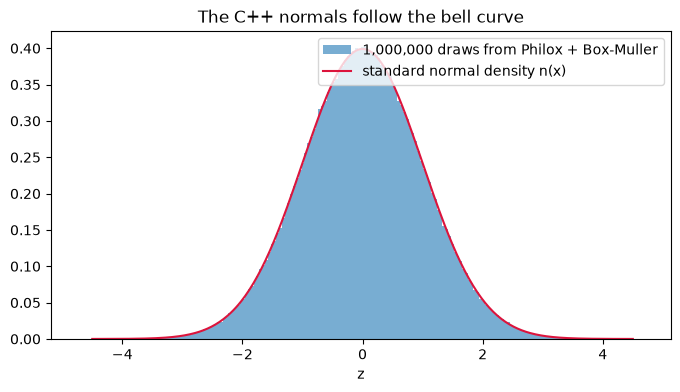

In [5]:
key = (2026, 10)
numpy_bits = np.random.Philox(key=np.array(key, dtype=np.uint64), counter=[0, 0, 0, 0]).random_raw(
    4
)
cpp_bits = _core.philox4x64((1, 0, 0, 0), key)  # numpy adds 1 to the counter before each block
print("numpy:", [hex(int(v)) for v in numpy_bits])
print("c++:  ", [hex(v) for v in cpp_bits])
print("identical:", [int(v) for v in numpy_bits] == cpp_bits)

z = cpp.normals(1_000_000, rng=0)
print(
    f"\n1,000,000 C++ normals: mean {z.mean():+.4f}, variance {z.var():.4f}, "
    f"kurtosis {stats.kurtosis(z, fisher=False):.3f} (normal: 0, 1, 3)"
)
print("normals 5 to 9 asked for directly:", np.array_equal(cpp.normals(5, rng=0, first=5), z[5:10]))

x = np.linspace(-4.5, 4.5, 400)
plt.figure(figsize=(8, 4))
plt.hist(z, bins=200, density=True, alpha=0.6, label="1,000,000 draws from Philox + Box-Muller")
plt.plot(x, stats.norm.pdf(x), color="crimson", label="standard normal density n(x)")
plt.xlabel("z")
plt.legend(loc="upper right")
plt.title("The C++ normals follow the bell curve")
plt.show()

## 5. Same normals in, same price out

Since the two sides can't share a random stream, they share the draws instead:
`mc_price_from_normals` takes the normals as an input. Feed both sides the same array and they
must give the same estimate and standard error, up to rounding. That compares the C++ Monte Carlo
with Python draw for draw, on top of the statistical tests.

In [ ]:
z = np.random.default_rng(42).standard_normal(500_000)
print("antithetic  control   Python estimate    C++ estimate       gap      SE gap")
for anti in (False, True):
    for control in (False, True):
        kw = {"z": z, "antithetic": anti, "control_variate": control}
        a = ope.mc_price_from_normals("call", *hull, **kw)
        b = cpp.mc_price_from_normals("call", *hull, **kw)
        print(
            f"{anti!s:10s}  {control!s:8s}  {a.estimate:.14f}  {b.estimate:.14f}  "
            f"{abs(a.estimate - b.estimate):.1e}  {abs(a.std_error - b.std_error):.1e}"
        )

antithetic  control   Python estimate    C++ estimate       gap      SE gap
False       False     4.75834912185179  4.75834912185179  8.9e-16  3.1e-17
False       True      4.76015140899326  4.76015140899324  2.1e-14  1.2e-16
True        False     4.76115824054314  4.76115824054314  3.6e-15  8.7e-19
True        True      4.75921931602212  4.75921931602208  4.2e-14  7.0e-19


## 6. More threads, same answer

`cpp.mc_price` splits the paths into fixed **chunks** of 16,384 draws. Each thread takes the next
free chunk, sums it on its own, and writes the chunk's totals (count, means, centered sums) to the
chunk's own slot. At the end, the slots are merged **in chunk order**, with the exact formula for
combining two groups' means and variances.

Floating-point addition isn't associative: `(a + b) + c` and `a + (b + c)` can
differ in the last bit. If each thread added up whatever paths it grabbed, the price would
change with the thread count, and even from run to run. With fixed chunks merged in order, a seed
gives the same bits on 1 thread or 8. Normal number i is always the same Philox draw, so Python
can replay the whole C++ run from `cpp.normals`.

In [ ]:
n = 1_000_000
runs = {
    t: cpp.mc_price("call", *hull, n_paths=n, control_variate=True, rng=7, threads=t)
    for t in (1, 2, 3, 4, 8)
}
for t, res in runs.items():
    print(f"{t} threads: estimate {res.estimate!r}, std error {res.std_error!r}")
print("all identical:", len(set(runs.values())) == 1)

replay = ope.mc_price_from_normals("call", *hull, z=cpp.normals(n, rng=7), control_variate=True)
gap = abs(replay.estimate - runs[8].estimate)
print(f"\nPython replay of the same draws: {replay.estimate!r} (gap {gap:.1e})")
print(
    f"Black-Scholes: {ope.price('call', *hull):.6f}, inside the 95% interval: "
    f"{runs[8].ci95[0] <= ope.price('call', *hull) <= runs[8].ci95[1]}"
)

1 threads: estimate 4.758285315248475, std error 0.0013647111515539196
2 threads: estimate 4.758285315248475, std error 0.0013647111515539196
3 threads: estimate 4.758285315248475, std error 0.0013647111515539196
4 threads: estimate 4.758285315248475, std error 0.0013647111515539196
8 threads: estimate 4.758285315248475, std error 0.0013647111515539196
all identical: True

Python replay of the same draws: 4.758285315248476 (gap 8.9e-16)
Black-Scholes: 4.759422, inside the 95% interval: True


## 7. How well the threads scale

Perfect scaling would make 8 threads 8× faster. Real machines fall short for three reasons:

- **Amdahl's law:** the part that stays serial (starting threads, merging the chunks) caps the
  speedup. If a fraction s of the work is serial, n threads give at most 1 / (s + (1 − s)/n).
- **Hyperthreads aren't cores:** 2 hardware threads share 1 core's arithmetic units, so going
  past the number of *physical* cores adds little for maths-heavy code.
- **Turbo:** a laptop runs 1 core faster than 4 at once, so the 1-thread time is flattered.

The plot shows what this machine does (CI runners have fewer cores, so the committed outputs
come from the laptop the tier was built on).

1 threads:   62.4 ms, speedup 1.00x
2 threads:   32.1 ms, speedup 1.95x
3 threads:   22.2 ms, speedup 2.82x
4 threads:   16.4 ms, speedup 3.80x
6 threads:   13.5 ms, speedup 4.62x
8 threads:   12.8 ms, speedup 4.88x


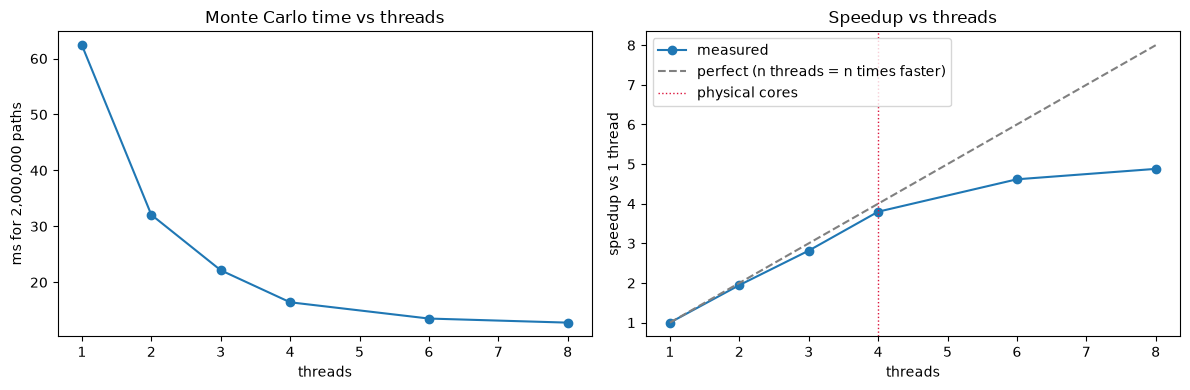

In [ ]:
threads = [1, 2, 3, 4, 6, 8]
n = 2_000_000
times = [
    best_ms(lambda t=t: cpp.mc_price("call", *hull, n_paths=n, rng=0, threads=t)) for t in threads
]
speedup = [times[0] / t for t in times]
for t, ms, s in zip(threads, times, speedup, strict=True):
    print(f"{t} threads: {ms:6.1f} ms, speedup {s:.2f}x")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(threads, times, "o-")
ax1.set_xlabel("threads")
ax1.set_ylabel("ms for 2,000,000 paths")
ax1.set_title("Monte Carlo time vs threads")
ax2.plot(threads, speedup, "o-", label="measured")
ax2.plot(threads, threads, "--", color="gray", label="perfect (n threads = n times faster)")
ax2.axvline(cpp.hardware_threads() / 2, color="crimson", lw=1, ls=":", label="physical cores")
ax2.set_xlabel("threads")
ax2.set_ylabel("speedup vs 1 thread")
ax2.set_title("Speedup vs threads")
ax2.legend()
plt.tight_layout()
plt.show()

## 8. What C++ buys, measured fairly

Comparing C++ with Python **loops** says little: anything compiled beats a Python loop by 10 to
100×, and nobody prices a chain that way. The fair comparison is NumPy, whose inner loops are
already compiled C. The full run (`bash benchmarks/run.sh`, larger sizes, Google Benchmark on the
C++ side) is in `benchmarks/RESULTS.md` and the README. Here is a smaller version, timed live.

                                   pure Python           NumPy    C++ 1 thread   C++ 8 threads
Black-Scholes, 20,000 calls            9.30 ms         0.82 ms         1.10 ms         0.59 ms
Monte Carlo, 200,000 paths           104.24 ms         3.21 ms         6.56 ms         1.81 ms
American tree, 500 steps              30.91 ms         5.28 ms         0.08 ms             n/a


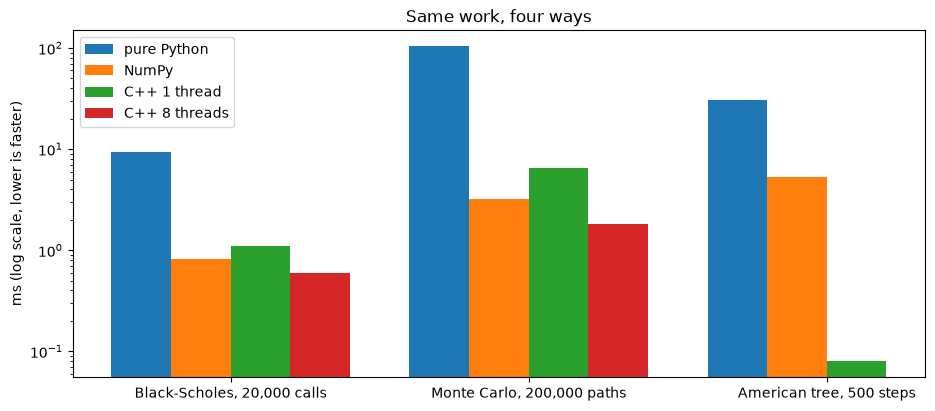

In [ ]:
import math
import random

S0, K0, T0, r0, s0 = hull
chain = {"S": 100.0, "K": np.linspace(50, 150, 20_000), "T": 1.0, "r": 0.03, "sigma": 0.25}


def bs_loop():
    out = []
    for k in chain["K"]:
        vs = 0.25
        d1 = (math.log(100 / k) + (0.03 + 0.5 * 0.25**2)) / vs
        d2 = d1 - vs
        out.append(
            100 * 0.5 * math.erfc(-d1 / math.sqrt(2))
            - k * math.exp(-0.03) * 0.5 * math.erfc(-d2 / math.sqrt(2))
        )
    return out


def mc_loop(n=200_000):
    gen, drift, vol, total = random.Random(0), (r0 - 0.5 * s0**2) * T0, s0 * math.sqrt(T0), 0.0
    for _ in range(n):
        total += max(S0 * math.exp(drift + vol * gen.gauss(0, 1)) - K0, 0.0)
    return math.exp(-r0 * T0) * total / n


def tree_loop(steps=500):
    S, K, T, r, sigma = 50.0, 50.0, 5 / 12, 0.10, 0.40
    dt = T / steps
    u = math.exp(sigma * math.sqrt(dt))
    p, disc = (math.exp(r * dt) - 1 / u) / (u - 1 / u), math.exp(-r * dt)
    v = [max(K - S * u ** (2 * j - steps), 0.0) for j in range(steps + 1)]
    for i in range(steps - 1, -1, -1):
        for j in range(i + 1):
            v[j] = max(disc * (p * v[j + 1] + (1 - p) * v[j]), K - S * u ** (2 * j - i))
    return v[0]


am = (50.0, 50.0, 5 / 12, 0.10, 0.40)
rows = {
    "Black-Scholes, 20,000 calls": [
        bs_loop,
        lambda: ope.price("call", **chain),
        lambda: cpp.price("call", **chain, threads=1),
        lambda: cpp.price("call", **chain),
    ],
    "Monte Carlo, 200,000 paths": [
        mc_loop,
        lambda: ope.mc_price("call", *hull, n_paths=200_000, rng=0),
        lambda: cpp.mc_price("call", *hull, n_paths=200_000, rng=0, threads=1),
        lambda: cpp.mc_price("call", *hull, n_paths=200_000, rng=0),
    ],
    "American tree, 500 steps": [
        tree_loop,
        lambda: ope.crr_price("put", *am, steps=500, american=True),
        lambda: cpp.crr_price("put", *am, steps=500, american=True),
        None,
    ],
}
labels = ["pure Python", "NumPy", "C++ 1 thread", f"C++ {cpp.hardware_threads()} threads"]
results = {name: [best_ms(f, 3) if f else np.nan for f in fns] for name, fns in rows.items()}
print(f"{'':30s}" + "".join(f"{lab:>16s}" for lab in labels))
for name, ms in results.items():
    print(f"{name:30s}" + "".join(f"{m:13.2f} ms" if m == m else f"{'n/a':>16s}" for m in ms))

fig, ax = plt.subplots(figsize=(11, 4.5))
width = 0.2
for i, lab in enumerate(labels):
    ax.bar(np.arange(3) + (i - 1.5) * width, [results[n][i] for n in rows], width, label=lab)
ax.set_yscale("log")
ax.set_xticks(np.arange(3), list(rows))
ax.set_ylabel("ms (log scale, lower is faster)")
ax.set_title("Same work, four ways")
ax.legend()
plt.show()

What the timings show, here and in the full run:

1. **The tree** is where C++ wins outright (about 30×): Python pays its interpreter overhead at
   every time step, and C++ doesn't.
2. **Black-Scholes and Monte Carlo on 1 thread** are close to NumPy, because NumPy's inner loops
   are compiled C too. The Monte Carlo split below shows why it's a tie: given the same normals,
   C++ prices about 2× faster, but its normals (Philox + Box-Muller: a log, a square root, a sine
   and a cosine per pair) cost about 2× more than NumPy's (PCG64 + the ziggurat method, a table
   lookup most of the time).
3. **Threads** bring the gain for Monte Carlo, because the paths are independent.

In [ ]:
g = np.random.default_rng(0)
z = g.standard_normal(1_000_000)
split = {
    "1,000,000 normals": (
        best_ms(lambda: g.standard_normal(1_000_000)),
        best_ms(lambda: cpp.normals(1_000_000, rng=0)),
    ),
    "pricing from given normals": (
        best_ms(lambda: ope.mc_price_from_normals("call", *hull, z=z)),
        best_ms(lambda: cpp.mc_price_from_normals("call", *hull, z=z)),
    ),
}
print(f"{'':28s}{'NumPy':>10s}{'C++':>10s}")
for name, (a, b) in split.items():
    print(f"{name:28s}{a:8.1f} ms{b:8.1f} ms")

                                 NumPy       C++
1,000,000 normals                9.6 ms    19.6 ms
pricing from given normals      18.8 ms    10.8 ms


## 9. Checked outside this notebook too

- **GoogleTest** (`cpp/tests/`, 20 tests): Hull's values, parity, the Philox known-answer vectors
  from Random123, normals' moments, same bits for any thread count, Hull's 5-step tree.
- **The same pytest suite on both sides:** every Tier 1 to 3 test that applies to a ported
  function runs twice, once on `ope` and once on `ope.cpp` (the `impl` fixture), plus
  `tests/test_cpp.py`, which compares the two directly on 100,000 random options.
- **Sanitizers in CI:** the C++ tests also run under AddressSanitizer (bad memory accesses),
  UndefinedBehaviorSanitizer (overflow, bad shifts, misaligned reads) and ThreadSanitizer (two
  threads touching the same memory without synchronization). All three are clean.
- **No `-ffast-math`:** it lets the compiler assume there's no infinity, and the degenerate
  Black-Scholes cases set d1 to ±∞ on purpose. `option.hpp` refuses to compile under it.

## 10. Try it yourself

1. **The C++ Black-Scholes pricer** (this tier's "try it yourself"): in
   `cpp/src/black_scholes.cpp`, delete the body of `call_value` and rewrite it from the formula
   C = S·e^(−qT)·N(d1) − K·e^(−rT)·N(d2). Rebuild with `uv sync`, then run the cell below: the gap
   to the Python price must stay under 1e-12.
2. In section 7, predict the speedup at 2 threads before you run it. Was Amdahl or turbo the
   bigger effect?
3. In section 5, set `z` to 11 draws and `antithetic=True`. What does the error say, and why does
   one pair not count as two samples?

In [11]:
# after rebuilding w/ your call_value
p = {
    "S": np.full(1000, 100.0),
    "K": np.linspace(50, 150, 1000),
    "T": 0.75,
    "r": 0.03,
    "sigma": 0.3,
    "q": 0.01,
}
print(
    "largest gap:", np.abs(np.asarray(cpp.call_price(**p)) - np.asarray(ope.call_price(**p))).max()
)

largest gap: 1.5987211554602254e-14
